# Лабораторная работа 8

# Обход бинарного дерева поиска. Поиск максимального и минимального значений

Немчинович Виктория Дмитриевна, 17.05.2025

## Задание 8.1. Центрированный обход бинарного дерева поиска

$\color{red}{Доопределим}$ классы `BinaryTree`, `BinaryNode`, `EmptyNode` из Лабораторной работы 7 за счет определения нового метода `lcr(self)`, реализующего центрированный обход бинарного дерева поиска.

Результатом вызова метода `lcr` для экземпляра класса `BinaryTree` должен быть список значений вершин дерева, отсортированных по возрастанию

In [1]:
class BinaryTree:
    def __init__(self):         # метод инициализации -- инициализирует экземпляр класса: метод обязан передать значения аргументов вызова атрибутам объекта.
        self.root = EmptyNode() # атрибут root, self - cтановится ссылкой на объект. Пока что у нас нет главной вершины, поэтому корень дерева -- EmptyNode()
        
    def __repr__(self):         # метод строкового представления экземпляра класса
        return repr(self.root)  # возвращает строковое представление для корня дерева root (как он это делает -- определим позже)
        
    def insert(self, value):    # метод вставки элемента в дерево
        self.root = self.root.insert(value)   # переопределяем атрибут экземпляра класса root, происходит вставка в корневую вершину дерева root (insert определим позже)
        
    def __contains__(self, value):
        return value in self.root
    
    def __len__(self):
        return len(self.root)
    
    def lcr(self):              # метод для центрированного обхода дерева
        return self.root.lcr()  # в свою очередь вызывается этот же метод для корневой вершины root

In [2]:
class EmptyNode:        
    def __repr__(self):   # метод строкового представления экземпляра класса
        return '*'        # возвращает *, если экземпляр класса EmptyNode
    
    def insert(self, value):                   # метод вставки новой вершины
        return BinaryNode(self, value, self)   # возвращает новый экземпляр класса BinaryNode со значением value, левое и правое поддерево которого определяются пустой вершиной
    
    def __contains__(self, value):
        return False
    
    def __len__(self):
        return 0
    
    def lcr(self):      # метод для центрированного обхода дерева
        return []       # так как элемент дерева пуст, то возвращается пустой список

In [3]:
class BinaryNode():
    
    def __init__(self, left, value, right): # метод инициализации -- обязан передать значения аргументов вызова атрибутам объекта
        self.left = left                    # self -- ссылка на объект (в будущем вместо него модно будет условно подставлять имя экземпляра класса), атрибут left -- хранит ссылку на корень левого поддерева 
        self.value = value                  # атрибут value -- храненит значение вершины
        self.right = right                  # атрибут right -- хранит ссылку на корень левого поддерева 
        self.count = 1
    
    def __repr__(self):                     # метод строкового представления экземпляра класса
        return "(%s, %s, %s)" % (repr(self.left), repr(self.value), repr(self.right)) # возвращает кортеж из строкового представления корня левой, правой вершин и значение вершины value
    
    def insert(self, value):                # метод вставки новой вершины
        self.count+=1                       # к атрибуту count добавляется 1 при вставке нового элемента в дерево
        if value < self.value:
            self.left = self.left.insert(value)
        else:
            self.right = self.right.insert(value)
        return self
    
    def __contains__(self, value):
        if value < self.value:
            return value in self.left
        elif value > self.value:
            return value in self.right
        else:
            return True
    
    def __len__(self):
        return self.count
    
    def lcr(self):     # метод для центрированного обхода дерева
        result = self.left.lcr() + [self.value] + self.right.lcr()   # значение вершины левого поддерева + корень + значение вершины правого поддерева
        return result
        

In [4]:
#[ |C, B, []|, A, |[[], E, []], D, [[], F, []]| ] # центрированный обход

Метод `lcr` класса `BinaryNode` возвращает список значений вершин, соответствующих центрированному обходу дерева с корнем `self.value` для экземпляра класса `BinaryNode`. Результирующий список формируется на основе вызова метода `lcr` для левого поддерева `self.left` и правого поддерева `self.right`, осуществляя конкатенацию списков по правилу центрированного обхода

### Алгоритм работы lcr

Для описание алгоритма использую `пример для понимания`, который находится ниже

Как работает `lcr`
Вызывается метод `lcr` для экземпляра класса `BTr` -- вызывается этот же метод для корневой вершины. Начинается центрированный обход. `result = [A]`
* Левое и правое поддеревья:

Вызывается `lcr` для левого поддерева и правого поддерева (они являются экземплярами класса `BN`) => `result = [B, [A], D]`. 
- Левое поддерево вершины А

Вершина `B` становится корневой вершиной в левом поддереве. Она -- экземпляр класса `BN`. Вызывается метод `lcr` для этого класса.
Проходим по ее левому поддереву. В ее корне - вершина `С`. `С` - экземпляр класса `BN` -- вызвается метод `lcr` для ее поддеревьев. Ее поддеревья --экземпляры класса `EmN`, метод `lcr` которого возвращает пустые списки. Вызывается этот метод и возвращает пустые списки.
- Поддеревья вершины В

Правое же поддерево вершины `B` также является экземпляром класса `EmN` -- вызывается метод `lcr` для класса `EmN` -- возвращает пустой список.
result = `[ [ [[], [C], []], [B], [] ], [A], D]`
- Правое поддерево вершины А

Аналогично и с правым поддеревом, корневая вершина которого - вершина D

### Выполнение

In [5]:
import matplotlib.pyplot as plt

In [6]:
import random as rnd

Cоздадим список из $10^3$ случайных чисел, равномерно распределенных на отрезке $[0, 100]$ с помощью функции `uniform` из модуля `random`

In [7]:
source_data = [rnd.uniform(0,100) for i in range(10**3)]
source_data;

Построим бинарное дерево поиска на основе списка `source_data`

In [8]:
source_data = [rnd.uniform(0,100) for i in range(10**3)]

tree = BinaryTree()
for i in source_data:
    tree.insert(i)

Выполним центрированный обход созданного бинарного дерева `tree`

In [9]:
sorted_data = tree.lcr()

In [10]:
sorted_data;

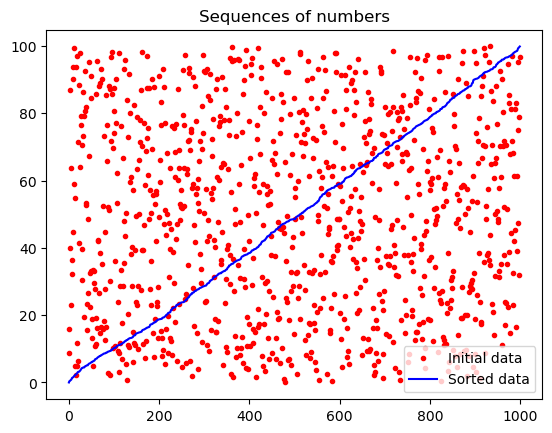

In [11]:
plt.plot(source_data,'r.', label='Initial data') # список исходных точек
plt.plot(sorted_data,'b-',label='Sorted data')   # список последовательности точек в порядке возрастания после центрированного обхода
plt.title('Sequences of numbers') # указание и отображение заголовка отображаемой визуализации
plt.legend() # размещениt легенды на осях

In [12]:
source_data = [rnd.uniform(0,100) for i in range(3)]

tree5 = BinaryTree()
for i in source_data:
    tree5.insert(i)
    print(tree5)
print(tree5)

(*, 94.80820214802807, *)
((*, 34.13374834273327, *), 94.80820214802807, *)
((*, 34.13374834273327, (*, 76.77282500159977, *)), 94.80820214802807, *)
((*, 34.13374834273327, (*, 76.77282500159977, *)), 94.80820214802807, *)


In [13]:
tree5.lcr()

[34.13374834273327, 76.77282500159977, 94.80820214802807]

## Обход по убыванию

* Переопределяем метод lcr() таким образом, чтобы в результирующий список сначала добавлялосб значение вершины правого поддерева, с примененным к нему методом lcr + корень + значение вершины левого поддерева


In [14]:
def lcr(self):     # метод для центрированного обхода дерева по убыванию
        result = self.right.lcr() + [self.value] + self.left.lcr()   # значение вершины правого поддерева + корень + значение вершины левого поддерева
        return result

$\color{red}{Переопределим}$ классы с учетом метода для центрированного обхода дерева по убыванию

In [15]:
class BinaryTree:
    def __init__(self):         # метод инициализации -- инициализирует экземпляр класса: метод обязан передать значения аргументов вызова атрибутам объекта.
        self.root = EmptyNode() # атрибут root, self - cтановится ссылкой на объект. Пока что у нас нет главной вершины, поэтому корень дерева -- EmptyNode()
        
    def __repr__(self):         # метод строкового представления экземпляра класса
        return repr(self.root)  # возвращает строковое представление для корня дерева root (как он это делает -- определим позже)
        
    def insert(self, value):    # метод вставки элемента в дерево
        self.root = self.root.insert(value)   # переопределяем атрибут экземпляра класса root, происходит вставка в корневую вершину дерева root (insert определим позже)
        
    def __contains__(self, value):
        return value in self.root
    
    def __len__(self):
        return len(self.root)
    
    def lcr(self):              # метод для центрированного обхода дерева
        return self.root.lcr()  # в свою очередь вызывается этот же метод для корневой вершины root

In [16]:
class EmptyNode:        
    def __repr__(self):   # метод строкового представления экземпляра класса
        return '*'        # возвращает *, если экземпляр класса EmptyNode
    
    def insert(self, value):                   # метод вставки новой вершины
        return BinaryNode(self, value, self)   # возвращает новый экземпляр класса BinaryNode со значением value, левое и правое поддерево которого определяются пустой вершиной
    
    def __contains__(self, value):
        return False
    
    def __len__(self):
        return 0
    
    def lcr(self):      # метод для центрированного обхода дерева
        return []       # так как элемент дерева пуст, то возвращается пустой список

In [17]:
class BinaryNode():
    
    def __init__(self, left, value, right): # метод инициализации -- обязан передать значения аргументов вызова атрибутам объекта
        self.left = left                    # self -- ссылка на объект (в будущем вместо него модно будет условно подставлять имя экземпляра класса), атрибут left -- хранит ссылку на корень левого поддерева 
        self.value = value                  # атрибут value -- храненит значение вершины
        self.right = right                  # атрибут right -- хранит ссылку на корень левого поддерева 
        self.count = 1
    
    def __repr__(self):                     # метод строкового представления экземпляра класса
        return "(%s, %s, %s)" % (repr(self.left), repr(self.value), repr(self.right)) # возвращает кортеж из строкового представления корня левой, правой вершин и значение вершины value
    
    def insert(self, value):                # метод вставки новой вершины
        self.count+=1                       # к атрибуту count добавляется 1 при вставке нового элемента в дерево
        if value < self.value:
            self.left = self.left.insert(value)
        else:
            self.right = self.right.insert(value)
        return self
    
    def __contains__(self, value):
        if value < self.value:
            return value in self.left
        elif value > self.value:
            return value in self.right
        else:
            return True
    
    def __len__(self):
        return self.count
    
    def lcr(self):     # метод для центрированного обхода дерева по убыванию
        result = self.right.lcr() + [self.value] + self.left.lcr()   # значение вершины правого поддерева + корень + значение вершины левого поддерева
        return result
        

In [18]:
import matplotlib.pyplot as plt

In [19]:
import random as rnd

Cоздадим список из $10^3$ случайных чисел, равномерно распределенных на отрезке $[0, 100]$ с помощью функции `uniform` из модуля `random`

In [20]:
source_data = [rnd.uniform(0,100) for i in range(5)]
source_data;

Построим бинарное дерево поиска на основе списка `source_data`

In [21]:
source_data = [rnd.uniform(0,100) for i in range(100)]

tree_inv = BinaryTree()
for i in source_data:
    tree_inv.insert(i)

Выполним центрированный обход созданного бинарного дерева `tree`

In [22]:
sorted_data = tree_inv.lcr()

In [23]:
sorted_data

[99.91682700124312,
 99.05004923533761,
 96.47550433666197,
 94.67204831861524,
 94.26574090852442,
 92.96179486668063,
 91.48135866339472,
 90.27790449829666,
 90.20732945213437,
 89.41584907204626,
 89.387364319354,
 88.76081567065353,
 86.58547550697543,
 84.75350348411304,
 84.56336555005151,
 84.27918250255364,
 84.25351840365249,
 82.6655850940334,
 81.39474129558273,
 78.61438673819112,
 77.2402034320628,
 77.0273347339874,
 75.70236542764147,
 75.00801216129122,
 73.66427307663109,
 73.25709138477026,
 72.51043047866557,
 72.31572309118349,
 71.84680060324294,
 71.5203560904985,
 70.97183990787083,
 70.91510850144533,
 69.85939174226111,
 69.11905011967947,
 68.57776046855314,
 66.3988629051901,
 61.89304697904405,
 61.28857806189991,
 61.14090289516329,
 58.93393644909777,
 58.115129987437186,
 56.87291781598762,
 56.45598528066002,
 54.58063855511166,
 54.09803734675304,
 53.05737222660639,
 52.785648869432755,
 52.54474337534535,
 51.78875367249363,
 51.30679317378083,
 51.1

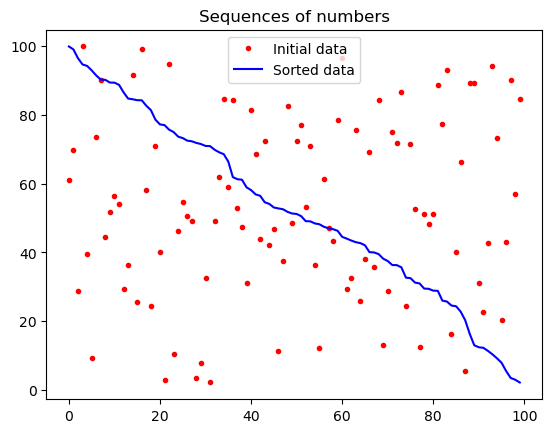

In [24]:
plt.plot(source_data,'r.', label='Initial data') # список исходных точек
plt.plot(sorted_data,'b-',label='Sorted data')   # список последовательности точек в порядке возрастания после центрированного обхода
plt.title('Sequences of numbers') # указание и отображение заголовка отображаемой визуализации
plt.legend() # размещениt легенды на осях

In [26]:
source_data = [rnd.uniform(0,100) for i in range(3)]

tree5 = BinaryTree()
for i in source_data:
    tree5.insert(i)
    print(tree5)
print(tree5)

(*, 61.1129557394574, *)
((*, 36.41270363985334, *), 61.1129557394574, *)
((*, 36.41270363985334, *), 61.1129557394574, (*, 79.70490083920221, *))
((*, 36.41270363985334, *), 61.1129557394574, (*, 79.70490083920221, *))


In [27]:
tree5.lcr()  # lcr по убыванию

[79.70490083920221, 61.1129557394574, 36.41270363985334]

## Задание 8.2. Нахождение минимального и максимального значения

$\color{red}{Доопределим}$ классы `BinaryTree`, `BinaryNode`, `EmptyNode` за счет определения метода `min(self)` и `max(self)` для нахождения минимального и максимального значений в дереве, соответственно.

Нахождение минимального и максимального значений в бинарном дереве поиска основано на центрированном обходе дерева.

Для поиска минимального значения нужно "двигаться" от корня дерева по левым поддеревьям. Для поиска максимального значения нужно "двигаться" от корня дерева по правым поддеревьям.

Реализацию нахождения минимального значения осуществим с помощью метода `min` для трех классов `BinaryTree`, `EmptyNode`, `BinaryNode`.

In [28]:
class BinaryTree:
    def __init__(self):         # метод инициализации -- инициализирует экземпляр класса: метод обязан передать значения аргументов вызова атрибутам объекта.
        self.root = EmptyNode() # атрибут root, self - cтановится ссылкой на объект. Пока что у нас нет главной вершины, поэтому корень дерева -- EmptyNode()
        
    def __repr__(self):         # метод строкового представления экземпляра класса
        return repr(self.root)  # возвращает строковое представление для корня дерева root (как он это делает -- определим позже)
        
    def insert(self, value):    # метод вставки элемента в дерево
        self.root = self.root.insert(value)   # переопределяем атрибут экземпляра класса root, происходит вставка в корневую вершину дерева root (insert определим позже)
        
    def __contains__(self, value):
        return value in self.root
    
    def __len__(self):
        return len(self.root)
    
    def lcr(self):              # метод для центрированного обхода дерева
        return self.root.lcr()  # в свою очередь вызывается этот же метод для корневой вершины root
    
    def min(self):              # метод нахождения минимального значения в бинарном дереве
        return self.root.min()  # в свою очередь вызывается этот же метод для корневой вершины root
    
    def max(self):              # метод нахождения максимального значения в бинарном дереве
        return self.root.max()  # в свою очередь вызывается этот же метод для корневой вершины root

In [29]:
class EmptyNode:        
    def __repr__(self):   # метод строкового представления экземпляра класса
        return '*'        # возвращает *, если экземпляр класса EmptyNode
    
    def insert(self, value):                   # метод вставки новой вершины
        return BinaryNode(self, value, self)   # возвращает новый экземпляр класса BinaryNode со значением value, левое и правое поддерево которого определяются пустой вершиной
    
    def __contains__(self, value):
        return False
    
    def __len__(self):
        return 0
    
    def lcr(self):      # метод для центрированного обхода дерева
        return []       # так как элемент дерева пуст, то возвращается пустой список
    
    def min(self):      # метод нахождения минимального значения в бинарном дереве
        return None     # так как элемент дерева пуст, то возвращается None
    
    def max(self):      # метод нахождения максимального значения в бинарном дереве
        return None     # так как элемент дерева пуст, то возвращается None
    

In [30]:
class BinaryNode():
    
    def __init__(self, left, value, right): # метод инициализации -- обязан передать значения аргументов вызова атрибутам объекта
        self.left = left                    # self -- ссылка на объект (в будущем вместо него модно будет условно подставлять имя экземпляра класса), атрибут left -- хранит ссылку на корень левого поддерева 
        self.value = value                  # атрибут value -- храненит значение вершины
        self.right = right                  # атрибут right -- хранит ссылку на корень левого поддерева 
        self.count = 1
    
    def __repr__(self):                     # метод строкового представления экземпляра класса
        return "(%s, %s, %s)" % (repr(self.left), repr(self.value), repr(self.right)) # возвращает кортеж из строкового представления корня левой, правой вершин и значение вершины value
    
    def insert(self, value):                # метод вставки новой вершины
        self.count+=1                       # к атрибуту count добавляется 1 при вставке нового элемента в дерево
        if value < self.value:
            self.left = self.left.insert(value)
        else:
            self.right = self.right.insert(value)
        return self
    
    def __contains__(self, value):
        if value < self.value:
            return value in self.left
        elif value > self.value:
            return value in self.right
        else:
            return True
    
    def __len__(self):
        return self.count
    
    def lcr(self):
        result = self.left.lcr() + [self.value] + self.right.lcr()
        return result
    
    def min(self):                                # метод нахождения минимального значения в бинарном дереве
        if isinstance(self.left, EmptyNode):      # если объект self.left является объектом класса EmN
            return self.value                     # верни последующий за ним элемент = self.value
        else:
            return self.left.min()                # иначе вызываем этот метод для левого поддерева
    
    def max(self):                                # метод нахождения максимального значения в бинарном дереве
        if isinstance(self.right, EmptyNode):     # если объект self.right является объектом класса EmN
            return self.value                     # верни предыдущий за ним элемент = self.value
        else:
            return self.right.max()               # иначе вызываем эту функцию для правого поддерева

In [31]:
new_tree = BinaryTree()

In [32]:
source_data = [5, 7, 3, 8, 2] # source_data = [rnd.uniform(0,100) for i in range(5)] - произвольные 5 элементов последовательности

In [33]:
for i in source_data:
    new_tree.insert(i)

In [34]:
new_tree

(((*, 2, *), 3, *), 5, (*, 7, (*, 8, *)))

Найдем минимальный элемент в этом бинарном дереве поиска

Метод `min` класса `BTr` вызывает метод `min` для корня. На текущем шаге **корень не пустой**,(=5) он представлен экземпляром класса `BN`.
На данном шаге `self.root` ссылался на объект типа `BN`, следовательно, происходит вызов метода `min` класса `BN`. Метод `min` класса `BN` вызывает метод `min` для левого поддерева (атрибут left хранит ссылку на корень левого поддерева). Корень левого поддерева представлен экземпляром класса `BN`(=3), следовательно, снова метод `min` класса `BN` вызывает метод `min` для левого поддерева. Левое поддерево представлено экземпляром класса `BN`(=2), следовательно, метод `min` класса `BN` вызывает метод `min` для левого поддерева. Левое поддерево представлено экземпляром класса `EmN`. Значит минимальным значением в непустом бинарном дереве поиска является значение `self.value` с корневым значением 2.

Проверяем, что найденный минимальный элемент бинарного дерева точно принадлежит бинарному дереву

In [35]:
min_el = new_tree.min()
print(min_el, min_el in new_tree)

2 True


### Выполнение и тестировка

In [36]:
import matplotlib.pyplot as plt

In [37]:
import random as rnd

In [38]:
source_data = [rnd.uniform(0,100) for i in range(10**3)]

tree1 = BinaryTree()
for i in source_data:
    tree1.insert(i)

In [39]:
min_el = tree1.min()
max_el = tree1.max()

Проверяем, что найденный минимальный и максимальный элементы бинарного дерева точно принадлежит бинарному дереву

In [40]:
print(min_el)
print(min_el in tree1)

0.13201372660770483
True


In [41]:
print(max_el)
print(max_el in tree1)

99.78323139422308
True


In [42]:
tree1;

In [43]:
source_data = [rnd.uniform(0,100) for i in range(5)]

In [49]:
import binaryTree # импортирую созданный модуль

In [51]:
source_data = [rnd.uniform(0,100) for i in range(5)]
tree2 = binaryTree.BinaryTree()
for i in source_data:
    tree2.insert(i)
    print(tree2)

(*, 30.261564639610583, *)
(*, 30.261564639610583, (*, 72.26516328093457, *))
(*, 30.261564639610583, (*, 72.26516328093457, (*, 78.66684486723021, *)))
((*, 10.480509289058904, *), 30.261564639610583, (*, 72.26516328093457, (*, 78.66684486723021, *)))
((*, 10.480509289058904, (*, 20.524875710489454, *)), 30.261564639610583, (*, 72.26516328093457, (*, 78.66684486723021, *)))


In [52]:
len(tree2)

5

In [53]:
tree2.min()

10.480509289058904

In [54]:
tree2.max()

78.66684486723021

In [55]:
tree2.lcr()

[10.480509289058904,
 20.524875710489454,
 30.261564639610583,
 72.26516328093457,
 78.66684486723021]

In [56]:
tree2

((*, 10.480509289058904, (*, 20.524875710489454, *)), 30.261564639610583, (*, 72.26516328093457, (*, 78.66684486723021, *)))

### Создание дерева с одним элементом, нахождение от него min и max

In [57]:
mytree = binaryTree.BinaryTree()
mytree.insert(1)
print(mytree)

(*, 1, *)


Минимальный и максимальный элемент дерева совпадают, так как в дереве находится только один элемент.

In [58]:
print(mytree.min())
print(mytree.max())

1
1


### Создание пустого дерева, нахождение от него min и max

По соглашению, при создании экземпляра класса EmptyNode, методы min и max возвращают None, так как элемент дерева пуст.

In [59]:
mytree1 = binaryTree.BinaryTree()
print(mytree1)

*


In [60]:
print(mytree1.min())
print(mytree1.max())

None
None


## Задание 8.4 Примеры пользовательских классов

In [3]:
class Temperature:
    def __init__(self, celsius=0):
        self._celsius = celsius
    
    @property
    def celsius(self):
        return self._celsius
    
    @celsius.setter
    def celsius(self, value):
        if value < -273.15:
            print("Температура не может быть ниже абсолютного нуля (-273.15°C)!")
        else:
            self._celsius = value
    
    @property
    def fahrenheit(self):
        return (self._celsius * 9/5) + 32
    
    def __str__(self):
        return f"{self._celsius:.1f}°C ({self.fahrenheit:.1f}°F)"

temp = Temperature(25)
print(temp)

temp.celsius = 30
print(temp)

temp.celsius = -300

try:
    temp.fahrenheit = 100
except AttributeError as e:
    print(f"Ошибка: {e}")

print(f"Текущая температура: {temp.celsius}°C")

25.0°C (77.0°F)
30.0°C (86.0°F)
Температура не может быть ниже абсолютного нуля (-273.15°C)!
Ошибка: can't set attribute 'fahrenheit'
Текущая температура: 30°C


In [5]:
class AnimalCounter:
    count = 0
    
    def __init__(self, name):
        self.name = name
        AnimalCounter.count += 1
    
    @staticmethod
    def get_count():
        return AnimalCounter.count
    
    def __str__(self):
        return f"Животное: {self.name}"

dog = AnimalCounter("Собака")
cat = AnimalCounter("Кошка")
bird = AnimalCounter("Попугай")

print(dog)
print(cat)
print(bird)

print(f"Всего животных: {AnimalCounter.get_count()}")

Животное: Собака
Животное: Кошка
Животное: Попугай
Всего животных: 3


In [13]:
class Vehicle:
    def __init__(self, brand, model):
        self.brand = brand
        self.model = model
    
    def start_engine(self):
        return "Двигатель запущен"
    
    def __str__(self):
        return f"{self.brand} {self.model}"

class Car(Vehicle):
    def drive(self):
        return "Машина поехала"
    
    def start_engine(self):
        return "Автомобиль: " + super().start_engine()

class Bicycle(Vehicle):
    def pedal(self):
        return "Велосипед едет"
    
    def start_engine(self):
        return "У велосипеда нет двигателя"

my_car = Car("Toyota", "Corolla")
my_bike = Bicycle("Stels", "Navigator")

print(my_car)
print(my_car.start_engine())
print(my_car.drive())

print("\n" + str(my_bike))
print(my_bike.start_engine())
print(my_bike.pedal())

Toyota Corolla
Автомобиль: Двигатель запущен
Машина поехала

Stels Navigator
У велосипеда нет двигателя
Велосипед едет
